# 06 · Pre-registered evaluation on 2022–2025

The plan — models, predictors, metric, goals and split — is in [`docs/preregistro_2022_2025.md`](../docs/preregistro_2022_2025.md) and was committed before any test result. Order of the git history: pre-registration → validation (α chosen) → test opened once.

| Set | Months | Rows |
|---|---|---|
| Train (validation inside: 4 blocks of 6 months, 2020–2021) | Jun 2018 – Dec 2021 | 387 |
| Test | Jan 2022 – Dec 2025 | 432 |

Goals: **(1)** the *forecast model* (only information available when forecasting) beats the seasonal rule by ≥ 10 % RMSE; **(2)** the *explanatory model* (actual weather and activity of the month) does too.

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cammesa.plots import style, BLUE, ORANGE, AQUA, YELLOW, RULE, INK2, MUTED
style(); pd.set_option('display.precision', 1); pd.set_option('display.width', 160)
FIG = '../docs/figures/'

In [2]:
from cammesa import extended as ex
import json
v = pd.read_csv('../results/ext_validacion.csv')
alphas = json.load(open('../results/ext_alphas.json'))
best = v[v.alpha.isna() | v.apply(lambda r: alphas.get(r.modelo) == r.alpha, axis=1)]
best.set_index('modelo').round(1)

,alpha,bloque 1,bloque 2,bloque 3,bloque 4,RMSE validación (GWh)
modelo,,,,,,
Regla: mismo mes del año anterior,NaN,105.8,81.0,158.4,116.8,115.5
Ridge del TP2,0.1,156.3,107.4,172.8,106.7,135.8
Modelo de pronóstico,100.0,110.4,85.5,123.4,81.5,100.2
Modelo explicativo,30.0,73.4,57.1,61.5,65.4,64.4


In [3]:
res = pd.read_csv('../results/ext_prueba_metricas.csv').set_index('modelo')
res.round(1)

,alpha,RMSE (GWh),MAE (GWh),MAPE (%),RMSE 2022,RMSE 2023,RMSE 2024,RMSE 2025,vs regla (%)
modelo,,,,,,,,,
Regla: mismo mes del año anterior,NaN,168.3,84.9,6.2,99.6,212.6,180.9,159.4,0.0
Ridge del TP2,0.1,165.1,84.1,5.9,132.6,173.8,182.7,166.8,-1.9
Modelo de pronóstico,100.0,153.0,79.0,5.7,87.8,162.5,184.5,159.8,-9.1
Modelo explicativo,30.0,106.0,57.7,4.3,65.7,94.0,137.6,113.5,-37.0


In [4]:
rule = res.loc[ex.RULE, 'RMSE (GWh)']
for name, goal in [('Modelo de pronóstico', 'Goal 1'), ('Modelo explicativo', 'Goal 2')]:
    r = res.loc[name, 'RMSE (GWh)']
    print(f"{goal}: {name} {r:.1f} vs rule {rule:.1f} GWh ({(r / rule - 1) * 100:+.1f} %) -> {'met' if r <= 0.9 * rule else 'not met'}")

Goal 1: Modelo de pronóstico 153.0 vs rule 168.3 GWh (-9.1 %) -> not met
Goal 2: Modelo explicativo 106.0 vs rule 168.3 GWh (-37.0 %) -> met


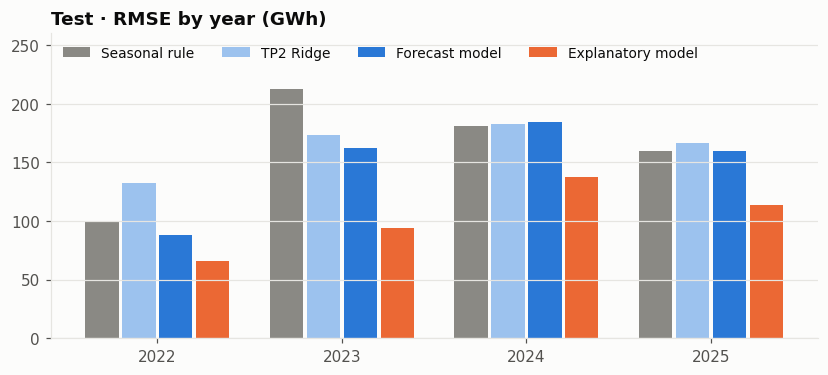

In [5]:
names = {ex.RULE: 'Seasonal rule', 'Ridge del TP2': 'TP2 Ridge', 'Modelo de pronóstico': 'Forecast model', 'Modelo explicativo': 'Explanatory model'}
years = ['2022', '2023', '2024', '2025']
fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.2
for i, (k, lab) in enumerate(names.items()):
    vals = [res.loc[k, f'RMSE {y}'] for y in years]
    ax.bar(np.arange(4) + (i - 1.5) * w, vals, width=w - 0.02, label=lab, color=[RULE, '#9cc2ee', BLUE, ORANGE][i])
ax.set_xticks(range(4), years); ax.legend(ncol=4, loc='upper left', fontsize=9); ax.set_ylim(0, 260)
ax.set_title('Test · RMSE by year (GWh)')
fig.savefig(FIG + 'fig06_eval_by_year.png'); plt.show()

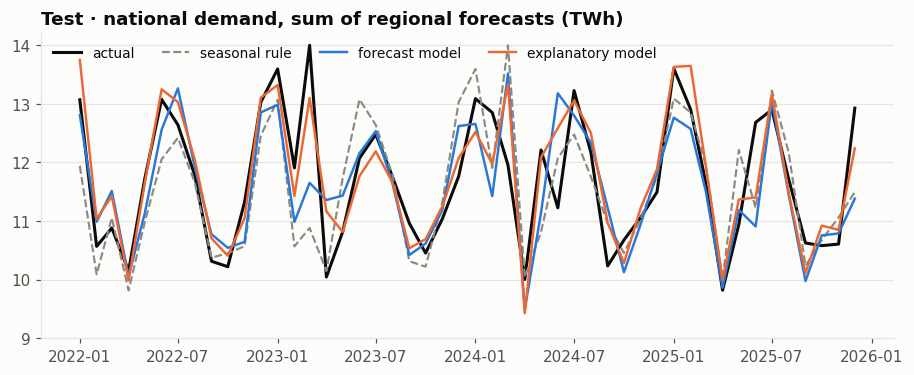

In [6]:
pred = pd.read_csv('../results/ext_prueba_predicciones.csv', dtype={'indice_tiempo': str})
tot = pred.groupby('indice_tiempo')[['demanda_MWh', ex.RULE, 'Modelo de pronóstico', 'Modelo explicativo']].sum() / 1e6
xs = pd.PeriodIndex(tot.index, freq='M').to_timestamp()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(xs, tot['demanda_MWh'], color='#0b0b0b', lw=2, label='actual')
ax.plot(xs, tot[ex.RULE], color=RULE, lw=1.4, ls='--', label='seasonal rule')
ax.plot(xs, tot['Modelo de pronóstico'], color=BLUE, lw=1.6, label='forecast model')
ax.plot(xs, tot['Modelo explicativo'], color=ORANGE, lw=1.6, label='explanatory model')
ax.set_title('Test · national demand, sum of regional forecasts (TWh)'); ax.legend(ncol=4, loc='upper left', fontsize=9)
ax.set_ylim(9, 14.2)
fig.savefig(FIG + 'fig07_eval_total.png'); plt.show()

**Results**

- **TP2 Ridge ≈ seasonal rule** again (−1.9 %), now over four new years: demand history alone does not beat the rule.
- **Goal 2 met:** with the actual weather and activity of the month the error falls 37 %. Weather, activity and tariffs explain much of what the rule misses — confirming the exploration on a period nobody had seen.
- **Goal 1 not met:** forecasting without knowing the month's weather improves 9.1 %, just short of the 10 % goal. It wins in 2022–2023 and ties in 2024–2025.
- The chosen α for the forecast model sits at the edge of the pre-registered grid (100). Trying larger values now would be post-hoc and is left as such.

## Classification: up or down vs last year

Pre-registered separately in [`docs/preregistro_clasificacion_2022_2025.md`](../docs/preregistro_clasificacion_2022_2025.md), after the regression test but before computing any classification metric. The goal classifiers say *up* when the pre-registered regression model predicts a positive year-over-year change; a classifier meets its goal if it beats the **persistence rule** on both F1 *up* and Cohen's kappa (kappa stops a classifier from winning by just saying *up* more often).

In [7]:
c = pd.read_csv('../results/ext_clf_prueba_metricas.csv').set_index('modelo')
cp = pd.read_csv('../results/ext_clf_prueba_predicciones.csv')
print(f"share of 'up' months in the test: {cp['sube'].mean():.0%}")
c[['F1 «sube»', 'Kappa', 'Exactitud balanceada', 'VN (baja ok)', 'FP', 'FN', 'VP (sube ok)', 'supera a la persistencia (F1 y kappa)']].round(2)

share of 'up' months in the test: 56%


,F1 «sube»,Kappa,Exactitud balanceada,VN (baja ok),FP,FN,VP (sube ok),supera a la persistencia (F1 y kappa)
modelo,,,,,,,,
Regla: persistencia,0.6,1.7e-01,0.6,103,88,88,153,NaN
Siempre «sube»,0.7,0.0e+00,0.5,0,191,0,241,False
Clasificador de pronóstico,0.7,3.7e-01,0.7,131,60,75,166,True
Clasificador explicativo,0.8,4.9e-01,0.7,121,70,36,205,True
Logística · variables de pronóstico,0.7,3.4e-01,0.7,123,68,72,169,True
Logística · variables explicativas,0.8,5.2e-01,0.8,128,63,38,203,True
SVM del TP3,0.6,9.0e-02,0.5,98,93,102,139,False


In [8]:
base = c.loc['Regla: persistencia']
for name, goal in [('Clasificador de pronóstico', 'Goal 1'), ('Clasificador explicativo', 'Goal 2')]:
    r = c.loc[name]
    ok = r['F1 «sube»'] > base['F1 «sube»'] and r['Kappa'] > base['Kappa']
    print(f"{goal}: {name} F1 {r['F1 «sube»']:.2f} / kappa {r['Kappa']:.2f} vs persistence {base['F1 «sube»']:.2f} / {base['Kappa']:.2f} -> {'met' if ok else 'not met'}")

Goal 1: Clasificador de pronóstico F1 0.71 / kappa 0.37 vs persistence 0.63 / 0.17 -> met
Goal 2: Clasificador explicativo F1 0.79 / kappa 0.49 vs persistence 0.63 / 0.17 -> met


**Classification results**

- **Both goals met.** Reading the sign of the forecast model beats persistence (F1 0.71 vs 0.63, kappa 0.37 vs 0.17) without knowing the month's weather; the explanatory one reaches F1 0.80 and kappa 0.49.
- *Always up* gets F1 0.72 because 56 % of test months were up — but kappa 0: it never spots a fall. That is why the goal also required kappa.
- The course's TP3 SVM (demand history only) is again below persistence (F1 0.59, kappa 0.09).
- Logistic regressions on the same predictors (reported, no goal) land within 0.01–0.03 of the goal classifiers.